# Forecasting Stock Volatility of Ambuja Cement Using the GARCH(1,1) Model and Walk-Forward Validation

## Konsep dasar volatilitas

1. Membuat dua deret return sintetis, “calm” (σ=1) dan “wild” (σ=4), lalu menghitung volatilitas harian dengan std() (0,72 vs 3,02).

In [1]:
import numpy as np
import pandas as pd

# Two synthetic return series (percent)
np.random.seed(42)
calm = pd.Series(
    np.random.normal(loc=0, scale=1, size=10),
    name="calm"
)
wild = pd.Series(
    np.random.normal(loc=0, scale=4, size=10),
    name="wild"
)

print("Calm  — daily volatility:", round(calm.std(), 4))
print("Wild  — daily volatility:", round(wild.std(), 4))

Calm  — daily volatility: 0.723
Wild  — daily volatility: 3.0213


2. Mengubah volatilitas harian menjadi tahunan dengan mengalikan √252 (11,48 vs 47,96).

In [2]:
annual_calm = calm.std() * np.sqrt(252)
annual_wild = wild.std() * np.sqrt(252)
print("Calm  — annual volatility:", round(annual_calm, 4))
print("Wild  — annual volatility:", round(annual_wild, 4))

Calm  — annual volatility: 11.4774
Wild  — annual volatility: 47.9616


3. Memplot return mentah dan return kuadrat. Return kuadrat dipakai sebagai proxy varians.

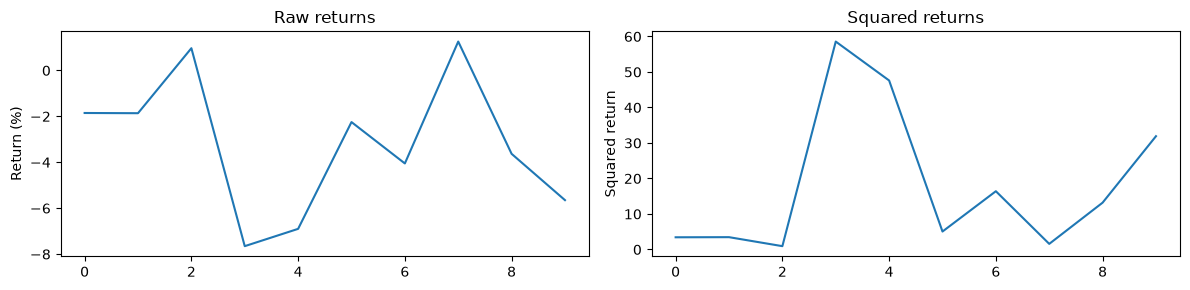

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
wild.plot(ax=axes[0], title="Raw returns")
(wild**2).plot(ax=axes[1], title="Squared returns")
axes[0].set_ylabel("Return (%)")
axes[1].set_ylabel("Squared return")
plt.tight_layout()
plt.show()

4. Memplot ACF dan PACF dari return kuadrat pada 500 data sintetis, sebagai demo cara mendeteksi efek ARCH.

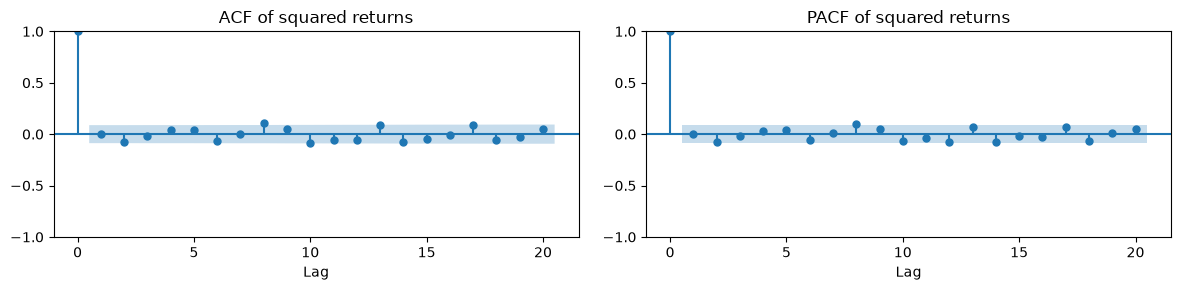

In [4]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Demonstrate with a longer synthetic series
np.random.seed(0)
long_returns = pd.Series(
    np.random.normal(0, 1, 500)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
plot_acf(long_returns**2, ax=axes[0], lags=20,
         title="ACF of squared returns")
plot_pacf(long_returns**2, ax=axes[1], lags=20,
          title="PACF of squared returns")
axes[0].set_xlabel("Lag")
axes[1].set_xlabel("Lag")
plt.tight_layout()
plt.show()

5. Kode versi manual (dikomentari) yang menghitung ACF/PACF sendiri, termasuk rekursi Durbin-Levinson.

In [5]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# def acf_manual(x, nlags):
#     x = np.asarray(x, dtype=float)
#     x = x - x.mean()
#     n = len(x)
#     denom = np.sum(x**2)
#     return np.array([np.sum(x[k:] * x[:n - k]) / denom for k in range(nlags + 1)])

# def pacf_manual(x, nlags):
#     """PACF lewat rekursi Durbin-Levinson."""
#     r = acf_manual(x, nlags)
#     pacf = np.zeros(nlags + 1)
#     pacf[0] = 1.0
#     phi = np.zeros((nlags + 1, nlags + 1))
#     phi[1, 1] = pacf[1] = r[1]
#     for k in range(2, nlags + 1):
#         num = r[k] - np.sum(phi[k - 1, 1:k] * r[k - 1:0:-1])
#         den = 1 - np.sum(phi[k - 1, 1:k] * r[1:k])
#         phi[k, k] = num / den
#         for j in range(1, k):
#             phi[k, j] = phi[k - 1, j] - phi[k, k] * phi[k - 1, k - j]
#         pacf[k] = phi[k, k]
#     return pacf

# def plot_corr(ax, values, n, title):
#     lags = np.arange(len(values))
#     ax.vlines(lags, 0, values)
#     ax.plot(lags, values, "o", markersize=4)
#     ci = 1.96 / np.sqrt(n)
#     ax.axhspan(-ci, ci, alpha=0.2)
#     ax.axhline(0, color="black", linewidth=0.8)
#     ax.set_title(title)
#     ax.set_xlabel("Lag")

# # Data sintetis
# np.random.seed(0)
# long_returns = pd.Series(np.random.normal(0, 1, 500))
# sq = (long_returns ** 2).to_numpy()

# nlags = 20
# fig, axes = plt.subplots(1, 2, figsize=(12, 3))
# plot_corr(axes[0], acf_manual(sq, nlags), len(sq), "ACF of squared returns")
# plot_corr(axes[1], pacf_manual(sq, nlags), len(sq), "PACF of squared returns")
# plt.tight_layout()
# plt.show()

6. Catatan pip install arch (dikomentari).

In [6]:
# pip install arch

7. Mencocokkan GARCH(1,1) pada data sintetis, hanya untuk demo API library arch.

In [7]:

from arch import arch_model

# Fit GARCH(1,1) to synthetic data (for API demo only)
toy_model = arch_model(
    long_returns, p=1, q=1, rescale=False
).fit(disp="off")

print(type(toy_model))

<class 'arch.univariate.base.ARCHModelResult'>


8. summary() menampilkan ringkasan model (log-likelihood, AIC, BIC, dan seterusnya).

In [8]:
# Quick look at the summary
toy_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                     Constant Mean - GARCH Model Results                      
==============================================================================
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -707.827
Distribution:                  Normal   AIC:                           1423.65
Method:            Maximum Likelihood   BIC:                           1440.51
                                        No. Observations:                  500
Date:                Thu, Nov 05 2026   Df Residuals:                      499
Time:                        09:10:37   Df Model:                            1
                                Mean Model                                
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu            -0.0303  4.484e-02     -0.677      0.499 [ -0.118,5.754e-02]
                               Volatility Model                              
=============================================================================
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
omega          0.0397  3.729e-02      1.064      0.287   [-3.341e-02,  0.113]
alpha[1]       0.0000  1.149e-02      0.000      1.000 [-2.253e-02,2.253e-02]
beta[1]        0.9592  4.559e-02     21.042  2.717e-98      [  0.870,  1.049]
=============================================================================

Covariance estimator: robust
"""

9. ACF dari residual terstandar kuadrat untuk memeriksa apakah model sudah menangkap efek volatilitas.

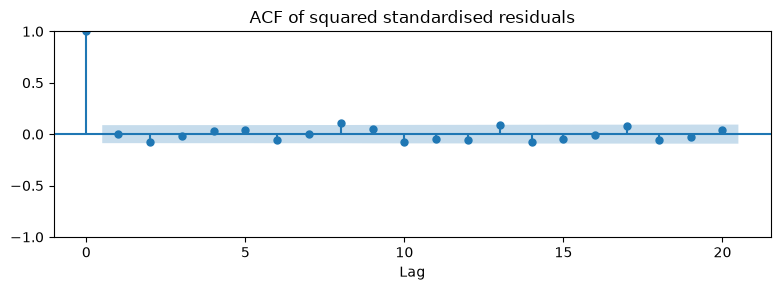

In [9]:
fig, ax = plt.subplots(figsize=(8, 3))
plot_acf(toy_model.std_resid**2, ax=ax, lags=20,
         title="ACF of squared standardised residuals")
ax.set_xlabel("Lag")
plt.tight_layout()
plt.show()

10. Demo bdate_range untuk membuat tanggal hari kerja (dipakai nanti untuk label hasil prediksi).

In [10]:
# Quick demo: business-day date range
start = pd.Timestamp("2023-01-06")  # a Friday
dates = pd.bdate_range(
    start=start + pd.DateOffset(days=1),
    periods=3
)
print([d.isoformat() for d in dates])

['2023-01-09T00:00:00', '2023-01-10T00:00:00', '2023-01-11T00:00:00']


## Persiapan data

1. Import library utama: json, pathlib, matplotlib, numpy, pandas, arch_model, mock, dan fungsi ACF/PACF.

In [11]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from arch import arch_model
from mock_alpha import activate_mock, deactivate_mock
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

2. activate_mock() mengaktifkan mock API.

In [12]:
activate_mock()

3. Request data harian AMBUJACEM.BSE (outputsize full) dan mengecek struktur respons: 5.225 record.

In [13]:
import requests

ticker = "AMBUJACEM.BSE"
url = (
    "https://www.alphavantage.co/query?"
    f"function=TIME_SERIES_DAILY&symbol={ticker}"
    "&outputsize=full&apikey=demo"
)
response = requests.get(url)
raw_data = response.json()

print("Response keys:", list(raw_data.keys()))
print(
    "Number of daily records:",
    len(raw_data["Time Series (Daily)"])
)

Response keys: ['Meta Data', 'Time Series (Daily)']
Number of daily records: 5225


4. Mengubah JSON menjadi DataFrame, mengambil hanya kolom close, mengubahnya ke float, mengonversi indeks ke DatetimeIndex, dan mengurutkan menaik.

In [14]:
# Extract daily time-series dict
ts_dict = raw_data["Time Series (Daily)"]

# Build DataFrame from the dict (dates become the index)
df_ambuja = pd.DataFrame.from_dict(ts_dict, orient="index")

# Keep only close price, cast to float, rename
df_ambuja = df_ambuja[["4. close"]].astype(float)
df_ambuja.columns = ["close"]

# Convert index to DatetimeIndex and sort ascending
df_ambuja.index = pd.to_datetime(df_ambuja.index)
df_ambuja.sort_index(ascending=True, inplace=True)

print("df_ambuja shape:", df_ambuja.shape)
df_ambuja.head()

df_ambuja shape: (5225, 1)


,close
2005-01-03,407.6001
2005-01-04,425.8501
2005-01-05,425.9501
2005-01-06,416.0501
2005-01-07,426.3001


5. Menghitung return persen (pct_change() * 100), membuang NaN, dan mengambil 2.500 observasi terakhir sebagai y_ambuja (2016-01-27 dst).

In [15]:
# Compute percentage returns
df_ambuja["return"] = df_ambuja['close'].pct_change() * 100 

# Drop NaN, keep last 2500 observations of "return" as a Series
y_ambuja = df_ambuja["return"].dropna().tail(2500).rename("return")

print("y_ambuja type:", type(y_ambuja))
print("y_ambuja shape:", y_ambuja.shape)
y_ambuja.head()

y_ambuja type: <class 'pandas.Series'>
y_ambuja shape: (2500,)


2016-01-27   -2.739726
2016-01-28    0.808555
2016-01-29    0.827943
2016-02-01    2.617398
2016-02-02   -1.625406
Name: return, dtype: float64

6. Fungsi wrangle_data(ticker, n_observations) yang membungkus seluruh langkah di atas. Dipakai untuk SUZLON.BSE sehingga menghasilkan y_suzlon (2.500 observasi).

In [16]:
def wrangle_data(
    ticker: str, n_observations: int
) -> pd.Series:
    """Fetch daily prices from the API and return percentage returns.

    Parameters
    ----------
    ticker : str
        Stock ticker symbol (used in the API URL).
    n_observations : int
        Number of return observations to keep (most recent).

    Returns
    -------
    pd.Series
        Name is "return", no NaN values, DatetimeIndex sorted
        ascending.
    """
    url = (
        "https://www.alphavantage.co/query?"
        f"function=TIME_SERIES_DAILY&symbol={ticker}"
        "&outputsize=full&apikey=demo"
    )
    response = requests.get(url)
    ts_dict = response.json()["Time Series (Daily)"]

    df = pd.DataFrame.from_dict(ts_dict, orient="index")
    df = df[["4. close"]].astype(float)
    df.columns = ["close"]
    df.index = pd.to_datetime(df.index)
    df.sort_index(ascending=True, inplace=True)

    df["return"] = df["close"].pct_change() * 100
    return df["return"].dropna().tail(n_observations)


y_suzlon = wrangle_data("SUZLON.BSE", n_observations=2500)

print("y_suzlon type:", type(y_suzlon))
print("y_suzlon shape:", y_suzlon.shape)
y_suzlon.head()

y_suzlon type: <class 'pandas.Series'>
y_suzlon shape: (2500,)


2016-02-04   -3.355705
2016-02-05    9.375000
2016-02-08    0.000000
2016-02-09   -3.809524
2016-02-10   -9.570957
Name: return, dtype: float64

7. deactivate_mock().

In [17]:
deactivate_mock()

8. Assertion: tipe Series, panjang 2.500, nama return, DatetimeIndex, terurut, tanpa NaN.

In [18]:
# -- y_ambuja checks --
assert isinstance(y_ambuja, pd.Series), (
    f"y_ambuja should be a pd.Series, got {type(y_ambuja)}"
)
assert len(y_ambuja) == 2500, (
    f"y_ambuja should have 2500 rows, got {len(y_ambuja)}"
)
assert y_ambuja.name == "return", (
    f"y_ambuja.name should be 'return', got '{y_ambuja.name}'"
)
assert isinstance(y_ambuja.index, pd.DatetimeIndex), (
    "y_ambuja.index should be a DatetimeIndex, "
    f"got {type(y_ambuja.index)}"
)
assert y_ambuja.index.is_monotonic_increasing, (
    "y_ambuja.index should be sorted ascending"
)
assert y_ambuja.isnull().sum() == 0, (
    f"y_ambuja has {y_ambuja.isnull().sum()} NaN values; "
    "expected 0"
)

# -- y_suzlon checks --
assert isinstance(y_suzlon, pd.Series), (
    f"y_suzlon should be a pd.Series, got {type(y_suzlon)}"
)
assert len(y_suzlon) == 2500, (
    f"y_suzlon should have 2500 rows, got {len(y_suzlon)}"
)
assert y_suzlon.isnull().sum() == 0, (
    f"y_suzlon has {y_suzlon.isnull().sum()} NaN values; "
    "expected 0"
)

print("All checks passed.")

All checks passed.


9. Plot return Suzlon dan Ambuja dalam satu grafik.

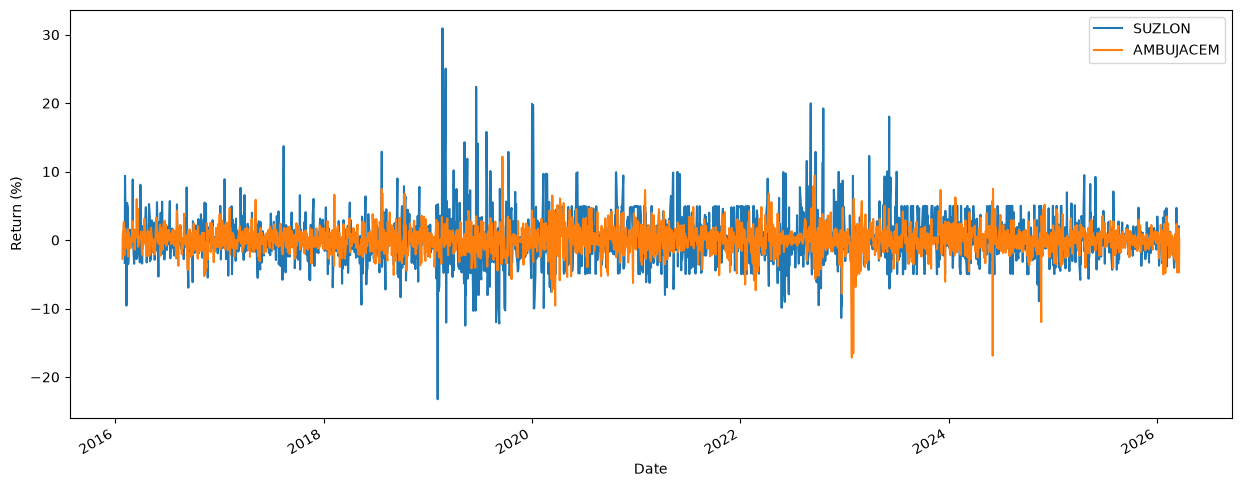

In [19]:
fig, ax = plt.subplots(figsize=(15, 6))
y_suzlon.plot(ax=ax, label="SUZLON")
y_ambuja.plot(ax=ax, label="AMBUJACEM")
ax.set_xlabel("Date")
ax.set_ylabel("Return (%)")
ax.legend()
plt.show()

10. Histogram distribusi return harian Ambuja.

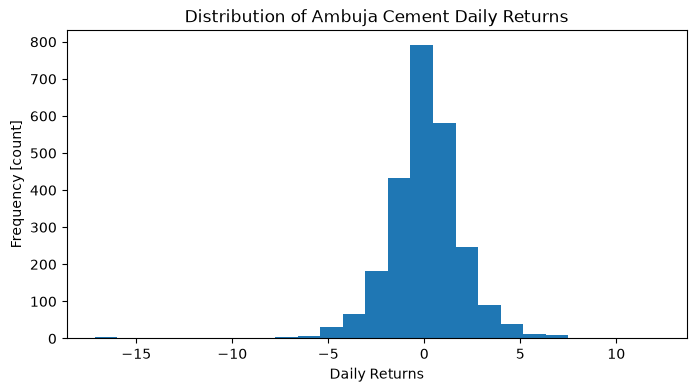

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_ambuja, bins=25)
ax.set_xlabel("Daily Returns")
ax.set_ylabel("Frequency [count]")
ax.set_title("Distribution of Ambuja Cement Daily Returns")
plt.show()

## Eksplorasi volatilitas

1. Menghitung volatilitas harian dan tahunan kedua saham. Suzlon 3,61% harian dan 57,35% tahunan; Ambuja 1,97% harian dan 31,34% tahunan.

In [21]:
suzlon_daily_vol = y_suzlon.std()
ambuja_daily_vol = y_ambuja.std()
suzlon_annual_vol = suzlon_daily_vol * np.sqrt(252)
ambuja_annual_vol = ambuja_daily_vol * np.sqrt(252)

print("Suzlon  — harian:", round(suzlon_daily_vol, 4),
      " | tahunan:", round(suzlon_annual_vol, 4))
print("Ambuja  — harian:", round(ambuja_daily_vol, 4),
      " | tahunan:", round(ambuja_annual_vol, 4))

Suzlon  — harian: 3.6129  | tahunan: 57.3529
Ambuja  — harian: 1.974  | tahunan: 31.3365


2. Rolling volatility 50 hari dari return Ambuja, diplot bersama return harian.

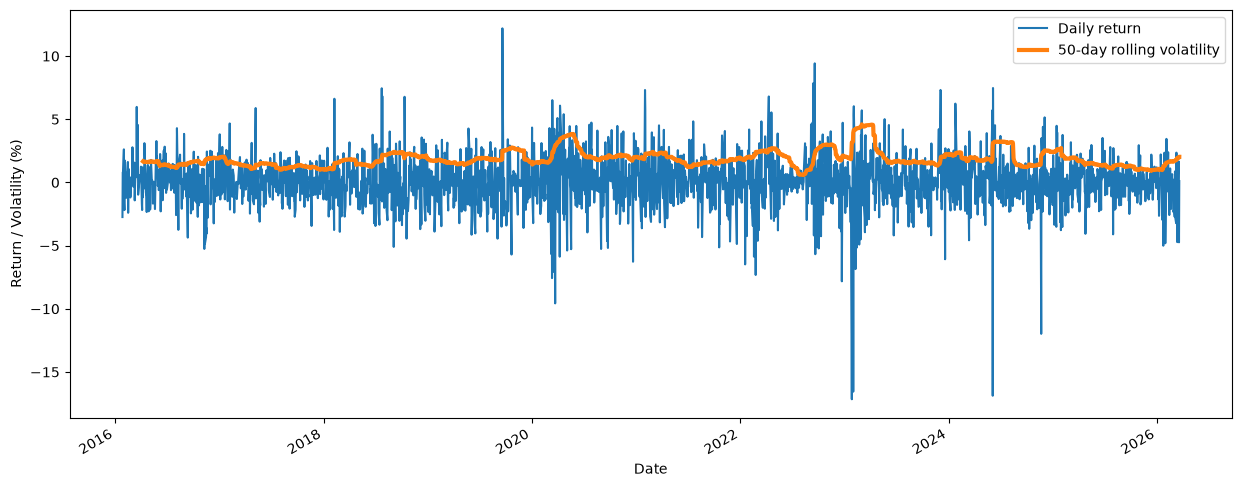

In [22]:
rolling_50d = y_ambuja.rolling(window=50).std().dropna()

fig, ax = plt.subplots(figsize=(15, 6))
y_ambuja.plot(ax=ax, label="Daily return")
rolling_50d.plot(
    ax=ax, label="50-day rolling volatility",
    linewidth=3
)
ax.set_xlabel("Date")
ax.set_ylabel("Return / Volatility (%)")
ax.legend()
plt.show()

3. Plot return kuadrat Ambuja untuk melihat pola pengelompokan volatilitas.

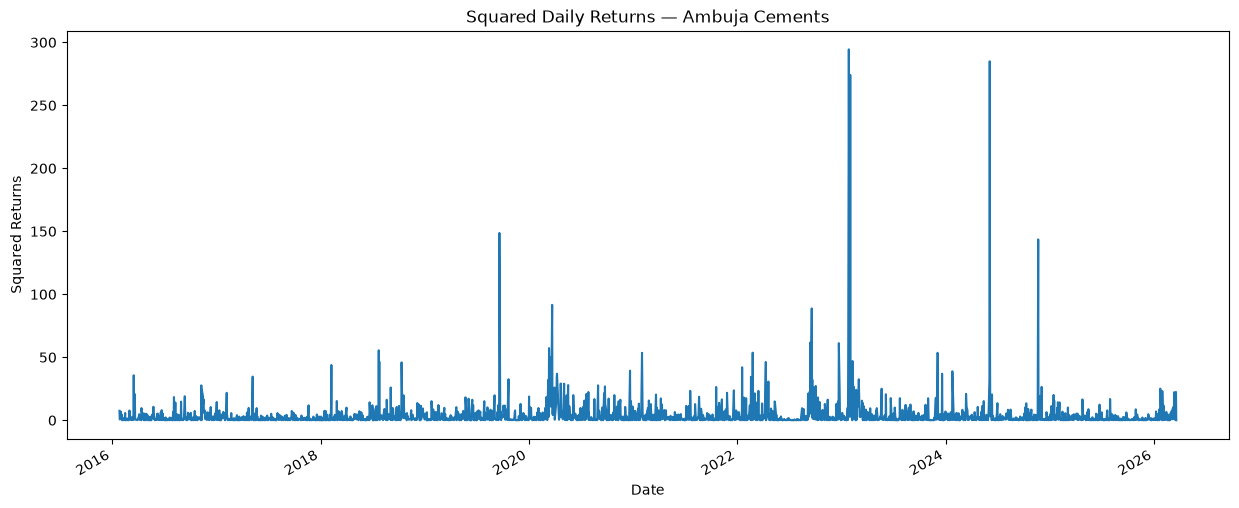

In [23]:
fig, ax = plt.subplots(figsize=(15, 6))
(y_ambuja ** 2).plot(ax=ax)
ax.set_xlabel("Date")
ax.set_ylabel("Squared Returns")
ax.set_title("Squared Daily Returns — Ambuja Cements")
plt.show()

4. ACF dan PACF dari return kuadrat Ambuja sebagai dasar pemilihan orde GARCH.

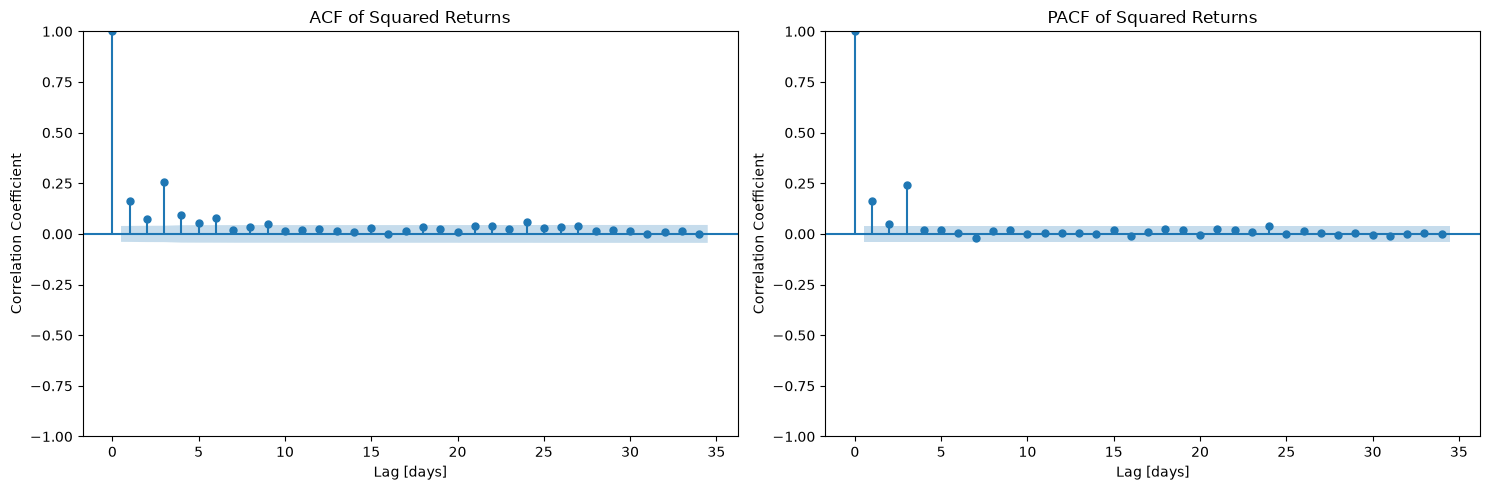

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_acf(y_ambuja ** 2, ax=axes[0])
axes[0].set_xlabel("Lag [days]")
axes[0].set_ylabel("Correlation Coefficient")
axes[0].set_title("ACF of Squared Returns")

plot_pacf(y_ambuja ** 2, ax=axes[1])
axes[1].set_xlabel("Lag [days]")
axes[1].set_ylabel("Correlation Coefficient")
axes[1].set_title("PACF of Squared Returns")

plt.tight_layout()
plt.show()

5. Assertion: volatilitas Suzlon lebih besar dari Ambuja, dan panjang rolling vol = n − 49.

In [25]:
assert suzlon_daily_vol > ambuja_daily_vol, (
    "Expected Suzlon daily vol > Ambuja daily vol, "
    f"got {suzlon_daily_vol:.4f} vs {ambuja_daily_vol:.4f}"
)
assert suzlon_annual_vol > ambuja_annual_vol, (
    "Expected Suzlon annual vol > Ambuja annual vol, "
    f"got {suzlon_annual_vol:.4f} vs {ambuja_annual_vol:.4f}"
)
assert len(rolling_50d) == len(y_ambuja) - 49, (
    f"Rolling volatility length should be {len(y_ambuja) - 49}, "
    f"got {len(rolling_50d)}"
)

print("All checks passed.")

All checks passed.


## Pemodelan GARCH

1. Membagi data 80:20 secara kronologis. y_train berisi 2.000 observasi (2016-01-27 s.d. 2024-03-06).

In [26]:
cutoff = int(len(y_ambuja) * 0.8)
y_train = y_ambuja.iloc[:cutoff]

print("y_train length:", len(y_train))
print("y_train date range:",
      y_train.index[0].date(), "to",
      y_train.index[-1].date())

y_train length: 2000
y_train date range: 2016-01-27 to 2024-03-06


2. Mencocokkan GARCH(1,1) pada data latih. AIC = 8169,74 dan BIC = 8192,14.

In [27]:
model = arch_model(y_train, p=1, q=1, rescale=False).fit(disp="off")

print("model type:", type(model))
print(f"AIC: {model.aic:.2f}  |  BIC: {model.bic:.2f}")
model.summary()

model type: <class 'arch.univariate.base.ARCHModelResult'>
AIC: 8169.74  |  BIC: 8192.14


<class 'statsmodels.iolib.summary.Summary'>
"""
                     Constant Mean - GARCH Model Results                      
==============================================================================
Dep. Variable:                 return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -4080.87
Distribution:                  Normal   AIC:                           8169.74
Method:            Maximum Likelihood   BIC:                           8192.14
                                        No. Observations:                 2000
Date:                Thu, Nov 05 2026   Df Residuals:                     1999
Time:                        09:10:41   Df Model:                            1
                                Mean Model                                
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0997  3.905e-02      2.554  1.065e-02 [2.319e-02,  0.176]
                              Volatility Model                             
===========================================================================
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
omega          0.2367      0.130      1.822  6.844e-02 [-1.791e-02,  0.491]
alpha[1]       0.1027  3.586e-02      2.865  4.177e-03  [3.244e-02,  0.173]
beta[1]        0.8379  6.107e-02     13.721  7.595e-43    [  0.718,  0.958]
===========================================================================

Covariance estimator: robust
"""

3. Memplot return latih bersama pita ±2 SD volatilitas kondisional.

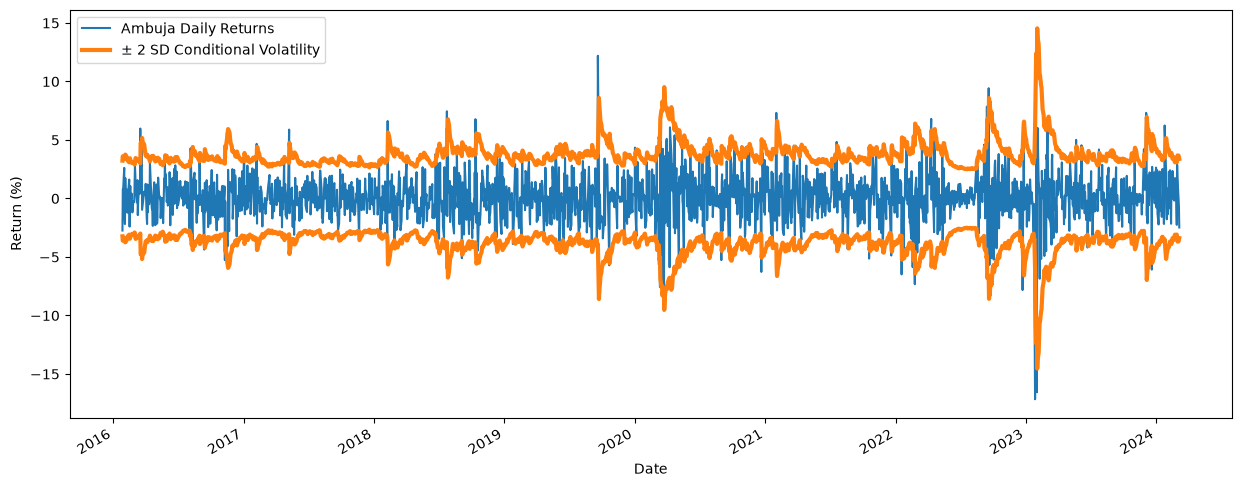

In [28]:
fig, ax = plt.subplots(figsize=(15, 6))

# Plot training returns
y_train.plot(ax=ax, label="Ambuja Daily Returns")

# Plot +2 SD conditional volatility
(2 * model.conditional_volatility).plot(
    ax=ax, color="C1",
    label="± 2 SD Conditional Volatility",
    linewidth=3
)

# Plot -2 SD conditional volatility (no extra legend entry)
(-2 * model.conditional_volatility.rename("")).plot(
    ax=ax, color="C1", linewidth=3
)

ax.set_xlabel("Date")
ax.set_ylabel("Return (%)")
ax.legend()
plt.show()

4. Plot residual terstandar.

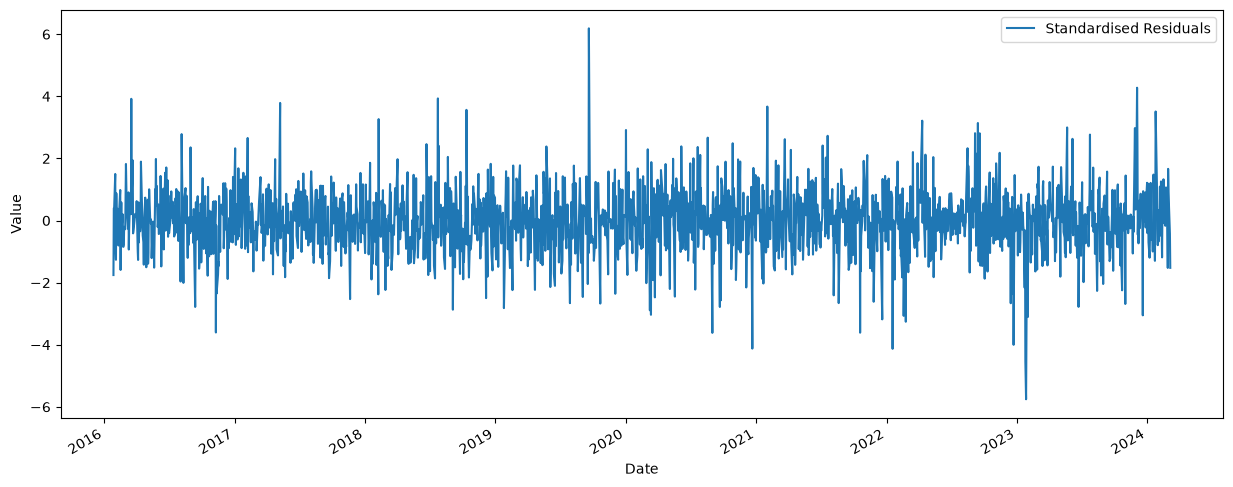

In [29]:
fig, ax = plt.subplots(figsize=(15, 6))
model.std_resid.plot(ax=ax, label="Standardised Residuals")
ax.set_xlabel("Date")
ax.set_ylabel("Value")
ax.legend()
plt.show()

5. Histogram residual terstandar untuk memeriksa kenormalan.

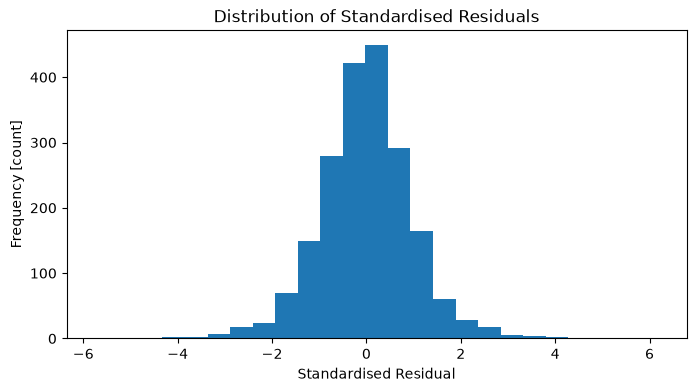

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(model.std_resid, bins=25)
ax.set_xlabel("Standardised Residual")
ax.set_ylabel("Frequency [count]")
ax.set_title("Distribution of Standardised Residuals")
plt.show()

6. ACF residual terstandar kuadrat. Jika tidak ada autokorelasi tersisa, model dianggap memadai.

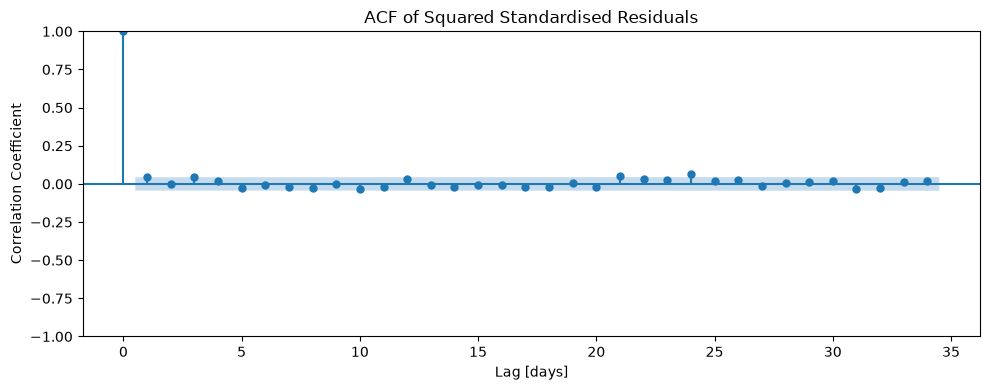

In [31]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(model.std_resid ** 2, ax=ax)
ax.set_xlabel("Lag [days]")
ax.set_ylabel("Correlation Coefficient")
ax.set_title(
    "ACF of Squared Standardised Residuals"
)
plt.tight_layout()
plt.show()

7. Assertion: model memiliki conditional_volatility dan std_resid, dan panjangnya sama dengan y_train.

In [32]:
assert hasattr(model, "conditional_volatility"), (
    "model should have a conditional_volatility attribute — "
    "did you fit the GARCH model?"
)
assert hasattr(model, "std_resid"), (
    "model should have a std_resid attribute"
)
assert len(model.conditional_volatility) == len(y_train), (
    "conditional_volatility length should match y_train, "
    f"got {len(model.conditional_volatility)} vs {len(y_train)}"
)

print(f"Model AIC: {model.aic:.2f}")
print(f"Model BIC: {model.bic:.2f}")
print("All checks passed.")

Model AIC: 8169.74
Model BIC: 8192.14
All checks passed.


## Walk-forward validation dan prediksi

1. Loop 500 iterasi dengan jendela data yang terus bertambah. Di tiap iterasi, model GARCH(1,1) dilatih ulang dan memprediksi volatilitas 1 hari ke depan. Hasilnya disimpan di y_test_wfv.

In [33]:
predictions = []
test_size = int(len(y_ambuja) * 0.2)

for i in range(test_size):
    # Expanding training window
    y_wf_train = y_ambuja.iloc[: -(test_size - i)]

    # Fit GARCH(1,1)
    wf_model = arch_model(
        y_wf_train, p=1, q=1, rescale=False
    ).fit(disp="off")

    # One-step-ahead volatility (sqrt of variance)
    next_vol = (
        wf_model.forecast(horizon=1, reindex=False)
        .variance.iloc[0, 0] ** 0.5
    )
    predictions.append(next_vol)

# Build Series from predictions
y_test_wfv = pd.Series(
    predictions,
    index=y_ambuja.tail(test_size).index
)

print("y_test_wfv type:", type(y_test_wfv))
print("y_test_wfv shape:", y_test_wfv.shape)
y_test_wfv.head()

y_test_wfv type: <class 'pandas.Series'>
y_test_wfv shape: (500,)


2024-03-07    1.821878
2024-03-11    1.754939
2024-03-12    1.680560
2024-03-13    1.828137
2024-03-14    2.305618
dtype: float64

2. Memplot return periode uji beserta pita ±2 SD volatilitas prediksi.

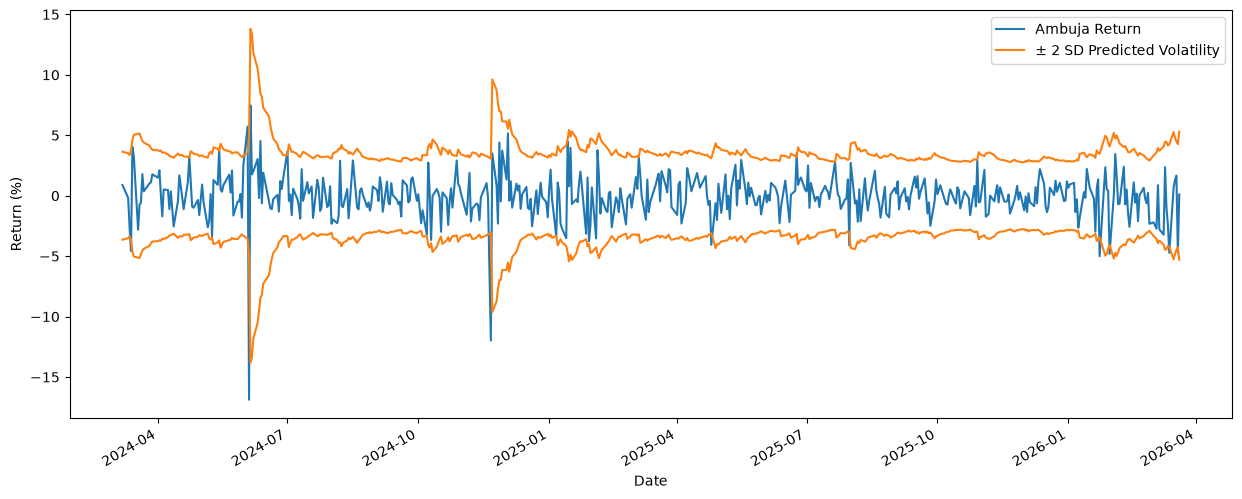

In [34]:
fig, ax = plt.subplots(figsize=(15, 6))

# Plot test-period returns
y_ambuja.tail(test_size).plot(
    ax=ax, label="Ambuja Return"
)

# Plot +2 SD predicted volatility
(2 * y_test_wfv).plot(
    ax=ax, color="C1",
    label="± 2 SD Predicted Volatility"
)

# Plot -2 SD predicted volatility
(-2 * y_test_wfv).plot(ax=ax, color="C1")

ax.set_xlabel("Date")
ax.set_ylabel("Return (%)")
ax.legend()
plt.show()

3. Assertion: tipe Series, panjang 500, dan semua nilai positif.

In [35]:
assert isinstance(y_test_wfv, pd.Series), (
    f"y_test_wfv should be a pd.Series, got {type(y_test_wfv)}"
)
assert len(y_test_wfv) == test_size, (
    f"y_test_wfv should have {test_size} entries, "
    f"got {len(y_test_wfv)}"
)
assert (y_test_wfv > 0).all(), (
    "All predicted volatilities should be positive"
)

print("All checks passed.")

All checks passed.


4. Prediksi varians 5 hari ke depan dari model utama (horizon=5).

In [36]:
prediction = model.forecast(
    horizon=5, reindex=False
).variance

print("prediction type:", type(prediction))
print("prediction shape:", prediction.shape)
prediction

prediction type: <class 'pandas.DataFrame'>
prediction shape: (1, 5)


,h.1,h.2,h.3,h.4,h.5
2024-03-06,3.319241,3.359025,3.396448,3.431652,3.464767


5. Membuat 5 tanggal hari kerja berikutnya dalam format ISO 8601.

In [37]:
# Forecast start: day after last training observation
start = prediction.index[0] + pd.DateOffset(days=1)

# Generate business-day dates
pred_dates = pd.bdate_range(
    start=start, periods=prediction.shape[1]
)

# Convert to ISO 8601 strings
pred_index = [d.isoformat() for d in pred_dates]

print("pred_index type:", type(pred_index))
print("pred_index length:", len(pred_index))
pred_index

pred_index type: <class 'list'>
pred_index length: 5


['2024-03-07T00:00:00',
 '2024-03-08T00:00:00',
 '2024-03-11T00:00:00',
 '2024-03-12T00:00:00',
 '2024-03-13T00:00:00']

6. Fungsi clean_prediction() yang mengubah varians menjadi volatilitas (akar kuadrat) dan menghasilkan dict {tanggal: volatilitas}. Diuji dengan horizon 10 hari: volatilitas naik pelan dari 1,82 ke 1,90.

In [38]:
def clean_prediction(prediction):
    """Konversikan DataFrame perkiraan varians menjadi sebuah dict.

    Parameter
    ----------
    prediction : pd.DataFrame
        Perkiraan varians dari ``ARCHModelForecast.variance``.

    Mengembalikan
    -------
    dict
        Kunci berupa string tanggal ISO 8601 (hari kerja).
        Nilai berupa volatilitas prediksi (simpangan baku).
    """
    # 1. Hitung tanggal mulai (gunakan kembali kode dari 8.3.7.2)
    start = prediction.index[0] + pd.DateOffset(days=1)
    pred_dates = pd.bdate_range(
        start=start, periods=prediction.shape[1]
    )
    pred_index = [d.isoformat() for d in pred_dates]

    # 2. Akar kuadrat dari varians = volatilitas
    data = prediction.values.flatten() ** 0.5

    pred_series = pd.Series(data, index=pred_index)
    return pred_series.to_dict()


# Uji dengan perkiraan 10 hari
prediction_10 = model.forecast(
    horizon=10, reindex=False
).variance
prediction_formatted = clean_prediction(prediction_10)

print("Tipe:", type(prediction_formatted))
print("Jumlah entri:", len(prediction_formatted))
prediction_formatted

Tipe: <class 'dict'>
Jumlah entri: 10


{'2024-03-07T00:00:00': 1.8218784751732153,
 '2024-03-08T00:00:00': 1.8327642262066715,
 '2024-03-11T00:00:00': 1.8429455416501068,
 '2024-03-12T00:00:00': 1.8524718227920052,
 '2024-03-13T00:00:00': 1.8613885012783733,
 '2024-03-14T00:00:00': 1.8697374261009598,
 '2024-03-15T00:00:00': 1.877557203684554,
 '2024-03-18T00:00:00': 1.884883498000572,
 '2024-03-19T00:00:00': 1.8917492964341132,
 '2024-03-20T00:00:00': 1.898185146167655}

7. Assertion: tipe dict, 10 entri, kunci string, nilai float positif.

In [39]:
assert isinstance(prediction_formatted, dict), (
    "prediction_formatted should be a dict, "
    f"got {type(prediction_formatted)}"
)
assert len(prediction_formatted) == 10, (
    "prediction_formatted should have 10 entries, "
    f"got {len(prediction_formatted)}"
)
assert all(isinstance(k, str) for k in prediction_formatted), (
    "All keys should be strings (ISO 8601 dates)"
)
assert all(
    isinstance(v, float) for v in prediction_formatted.values()
), (
    "All values should be floats (volatility)"
)
assert all(v > 0 for v in prediction_formatted.values()), (
    "All volatility values should be positive"
)

print("All checks passed.")
print("Sample:", dict(list(prediction_formatted.items())[:3]))

All checks passed.
Sample: {'2024-03-07T00:00:00': 1.8218784751732153, '2024-03-08T00:00:00': 1.8327642262066715, '2024-03-11T00:00:00': 1.8429455416501068}


Kesimpulan Singkat

- Alur kerja lengkap dari data sampai prediksi. 
- Notebook mengambil data harga, menghitung return, mengeksplorasi volatilitas, melatih GARCH(1,1), memvalidasi dengan walk-forward, lalu membungkus hasilnya menjadi dict siap pakai (cocok untuk API).
- Suzlon jauh lebih berisiko daripada Ambuja. 
- Volatilitas tahunan Suzlon sekitar 57,4% dibanding Ambuja sekitar 31,3%.
- Volatilitas Ambuja tidak konstan. 
- Rolling volatility, return kuadrat, dan ACF/PACF menunjukkan volatility clustering, sehingga GARCH layak dipakai.
- Hasil model. GARCH(1,1) dilatih pada 2.000 observasi (AIC 8169,74). 
- Prediksi volatilitas harian 10 hari ke depan berkisar 1,82% sampai 1,90% dan naik perlahan. 
- Ini menandakan volatilitas kembali ke rata-rata jangka panjang, yang konsisten dengan sifat GARCH.

Catatan.
- Walk-forward dengan 500 kali pelatihan ulang memberi evaluasi yang realistis, tetapi lambat.
- Notebook memakai distribusi Normal, padahal data saham biasanya berekor tebal. Distribusi Student-t bisa dicoba.
- Notebook hanya menilai prediksi secara visual (pita ±2 SD). 
- Belum ada metrik kuantitatif seperti RMSE atau uji cakupan.